# Alcohol impairment in fatal crashes on U.S. holidays

### Research Question: How does the proportion of fatal motor-vehicle crashes involving an alcohol-impaired driver differ between U.S. holiday dates and comparable non-holiday dates, and how has this relationship changed from 2019 to 2024?

In [1]:
import numpy as np
import pandas as pd
import holidays
from datetime import timedelta
import matplotlib.pyplot as plt

### Load and prepare the crash data

We first combined the FARS crash-level data from 2019 through 2024. Each row represents one fatal crash. We added the year to each dataset before combining them so that crashes from different years could be identified correctly. 

In [2]:
annual_crashes = []

for year in range(2019, 2025):
    filename = "accident.CSV" if year == 2019 else "accident.csv"
    file_path = f"raw/FARS{year}NationalCSV/{filename}"
    data = pd.read_csv(file_path, encoding="latin1", low_memory=False)
    
    # Remove the extra character from column names
    data.columns = data.columns.str.replace("ï»¿", "", regex=False)
    data["YEAR"] = year
    annual_crashes.append(data)

crashes = pd.concat(annual_crashes, ignore_index=True)

print(crashes["YEAR"].value_counts().sort_index())
print("Total crashes", len(crashes))

crashes.to_csv(
    "processed/combined_accident_2019_2024.csv",
    index=False)

YEAR
2019    33487
2020    35935
2021    39785
2022    39422
2023    37769
2024    36297
Name: count, dtype: int64
Total crashes 222695


### Checking for the duplicate crashes

In [3]:
duplicate_crashes = crashes.duplicated(
    subset=["YEAR", "ST_CASE"]
).sum()

print("Duplicate crashes:", duplicate_crashes)

Duplicate crashes: 0


In [4]:
columns_to_keep = ["YEAR", "ST_CASE", "MONTH", "DAY", "HOUR", "DAY_WEEK", "STATE", "WEATHER", "WEATHERNAME"]
crash_data = crashes[columns_to_keep].copy()

print("Rows and columns", crash_data.shape)
crash_data.head()

Rows and columns (222695, 9)


,YEAR,ST_CASE,MONTH,DAY,HOUR,DAY_WEEK,STATE,WEATHER,WEATHERNAME
0,2019,10001,2,7,12,5,1,1,Clear
1,2019,10002,1,23,18,4,1,2,Rain
2,2019,10003,1,22,19,3,1,10,Cloudy
3,2019,10004,1,22,3,3,1,1,Clear
4,2019,10005,1,18,5,6,1,5,"Fog, Smog, Smoke"


### Checking for missing values

FARS uses number codes for some missing values. We changed those codes in the hour and weather columns so pandas could count them. About 0.75% of crashes had a missing hour, and 5.04% had missing weather. We kept these rows because we could still use the crash date.

In [5]:
missing = float("nan")

crash_data["HOUR"] = crash_data["HOUR"].replace(99, missing)
crash_data["WEATHER"] = crash_data["WEATHER"].replace([98, 99], missing)

print(crash_data[["HOUR", "WEATHER"]].isna().sum())

#Calculating the percentage of crashes missing hour or weather
total_crashes = len(crash_data)
missing_counts = crash_data[["HOUR", "WEATHER"]].isna().sum()
missing_percentages = missing_counts / total_crashes * 100

print("Percentage of crashes with missing values")
print(missing_percentages.round(2))

HOUR        1668
WEATHER    11234
dtype: int64
Percentage of crashes with missing values
HOUR       0.75
WEATHER    5.04
dtype: float64


In [6]:
#Creating a crash date from year, month, and day
crash_data["DATE"] = pd.to_datetime(crash_data[["YEAR", "MONTH", "DAY"]])

print(crash_data[["YEAR", "MONTH", "DAY", "DATE"]].head())

   YEAR  MONTH  DAY       DATE
0  2019      2    7 2019-02-07
1  2019      1   23 2019-01-23
2  2019      1   22 2019-01-22
3  2019      1   22 2019-01-22
4  2019      1   18 2019-01-18


### Creating the date and finding holidays


We combined the year, month, and day into one date. Then we used the holidays package to find New Year’s Day, Memorial Day, Independence Day, Labor Day, Thanksgiving Day, and Christmas Day. We used the actual calendar dates, which gave us 36 holiday dates across six years.

In [7]:
us_holidays = holidays.US(years=range(2019, 2025), observed=False)

holiday_names = {
    "New Year's Day",
    "Memorial Day",
    "Independence Day",
    "Labor Day",
    "Thanksgiving Day",
    "Christmas Day"
}

holiday_lookup = {
    date: name
    for date, name in us_holidays.items()
    if name in holiday_names
}
holiday_dates = list(holiday_lookup)

matched_names = crash_data["DATE"].dt.date.map(holiday_lookup)
is_holiday_day = matched_names.notna()

crash_data["HOLIDAY_DAY"] = is_holiday_day.astype(int)
crash_data["HOLIDAY_NAME"] = matched_names

print("Holiday dates", len(holiday_dates))
print(crash_data["HOLIDAY_DAY"].value_counts().sort_index())

Holiday dates 36
HOLIDAY_DAY
0    218657
1      4038
Name: count, dtype: int64


## Adding Alcohol-Impairment Data

To identify whether a fatal crash involved an alcohol-impaired driver, we used the FARS MIDRVACC files. These files contain ten imputed versions of the highest driver BAC for each crash. We first combined the MIDRVACC files from 2019 through 2024.

In [8]:
annual_bac = []

for year in range(2019, 2025):
    file_path = f"raw/FARS{year}NationalCSV/MIDRVACC.CSV"

    data = pd.read_csv(
        file_path,
        encoding="latin1",
        low_memory=False
    )

    data.columns = data.columns.str.replace("ï»¿", "", regex=False)
    data["YEAR"] = year

    annual_bac.append(data)

bac_data = pd.concat(annual_bac, ignore_index=True)

print(bac_data["YEAR"].value_counts().sort_index())
print("Total BAC rows:", len(bac_data))

bac_data.to_csv(
    "processed/combined_midrvacc_2019_2024.csv",
    index=False
)

YEAR
2019    33424
2020    35857
2021    39738
2022    39359
2023    37712
2024    36229
Name: count, dtype: int64
Total BAC rows: 222319


Before merging the BAC data with the crash data, we checked the columns, number of rows, and whether any crash appeared more than once.

In [9]:
print("BAC rows and columns", bac_data.shape)

print(
    "Duplicate BAC crashes",
    bac_data.duplicated(subset=["YEAR", "ST_CASE"]).sum()
)

BAC rows and columns (222319, 12)
Duplicate BAC crashes 0


### Merging BAC Data with Crash Data

We merged the BAC data with the crash-level dataset using `YEAR` and `ST_CASE`. This keeps the final dataset at one row per crash while adding the ten imputed BAC values.

In [10]:
crash_bac = crash_data.merge(
    bac_data,
    on=["YEAR", "ST_CASE"],
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Total crashes", len(crash_bac))
print(crash_bac["_merge"].value_counts())

Total crashes 222695
_merge
both          222319
left_only        376
right_only         0
Name: count, dtype: int64


We found matching BAC records for 222,319 crashes. We excluded the 376 crashes without a matching BAC record

In [11]:
analysis_data = crash_bac[crash_bac["_merge"] == "both"].copy()
bac_columns = [f"A{i}" for i in range(1, 11)]
print("Missing BAC values:", analysis_data[bac_columns].isna().sum().sum())

for number in range(1, 11):
    bac_column = f"A{number}"
    outcome_column = f"IMPAIRED_{number}"

    analysis_data[outcome_column] = (analysis_data[bac_column] >= 8).astype(int)

print("Crashes with BAC data", len(analysis_data))
analysis_data[["A1", "IMPAIRED_1", "A2", "IMPAIRED_2"]].head()

Missing BAC values: 0
Crashes with BAC data 222319


,A1,IMPAIRED_1,A2,IMPAIRED_2
0,0.0,0,0.0,0
1,0.0,0,0.0,0
2,0.0,0,0.0,0
3,0.0,0,0.0,0
4,23.0,1,23.0,1


Choose comparison dates


We chose two nearby dates with the same weekday for each holiday. For example, we compared Thanksgiving with the Thursday before and the Thursday after. We used different weeks for Christmas and New Year’s Day to avoid other holidays. The final study table had 4,035 crashes on holiday dates and 6,963 on comparison dates.

In [12]:
comparison_dates = []

for date in holiday_dates:
    holiday_name = us_holidays[date]

    if holiday_name == "New Year's Day":
        shifts = [7, 21]
    elif holiday_name == "Christmas Day":
        shifts = [-14, -7]
    else:
        shifts = [-7, 7]

    for days in shifts:
        comparison_dates.append(date + timedelta(days=days))

is_holiday = analysis_data["HOLIDAY_DAY"] == 1
is_comparison = analysis_data["DATE"].dt.date.isin(comparison_dates)

study_data = analysis_data[is_holiday | is_comparison].copy()
study_data["GROUP"] = study_data["HOLIDAY_DAY"].map({
    0: "Comparison",
    1: "Holiday"
})

print("Comparison dates", len(comparison_dates))
print(study_data["HOLIDAY_DAY"].value_counts().sort_index())

Comparison dates 72
HOLIDAY_DAY
0    6963
1    4035
Name: count, dtype: int64


Compare the results


We calculated the percentage of fatal crashes that involved an impaired driver for each BAC version. Then we averaged the ten percentages. Across all six years, the estimated share was 38.64% on holiday dates and 27.82% on comparison dates.

In [13]:
outcome_columns = [f"IMPAIRED_{number}" for number in range(1, 11)]

rates_by_version = study_data.groupby("HOLIDAY_DAY")[outcome_columns].mean()
percent_impaired = rates_by_version.mean(axis=1) * 100

comparison_pct = percent_impaired.loc[0]
holiday_pct = percent_impaired.loc[1]

print("Comparison days (%)", round(comparison_pct, 2))
print("Holiday days (%)", round(holiday_pct, 2))
print("Difference (percentage points)", round(holiday_pct - comparison_pct, 2))

Comparison days (%) 27.82
Holiday days (%) 38.64
Difference (percentage points) 10.82


In [14]:
rates_by_year = study_data.groupby(["YEAR", "HOLIDAY_DAY"])[outcome_columns].mean()
percent_by_year = rates_by_year.mean(axis=1) * 100

yearly_table = percent_by_year.unstack()
yearly_table = yearly_table.rename(columns={0: "Comparison %", 1: "Holiday %"})

yearly_table["Gap (percentage points)"] = (
    yearly_table["Holiday %"] - yearly_table["Comparison %"]
)

yearly_table.round(2)

HOLIDAY_DAY,Comparison %,Holiday %,Gap (percentage points)
YEAR,,,
2019,22.54,33.59,11.05
2020,27.87,42.52,14.65
2021,31.48,41.87,10.38
2022,31.41,37.83,6.42
2023,27.00,36.07,9.07
2024,24.80,39.14,14.34


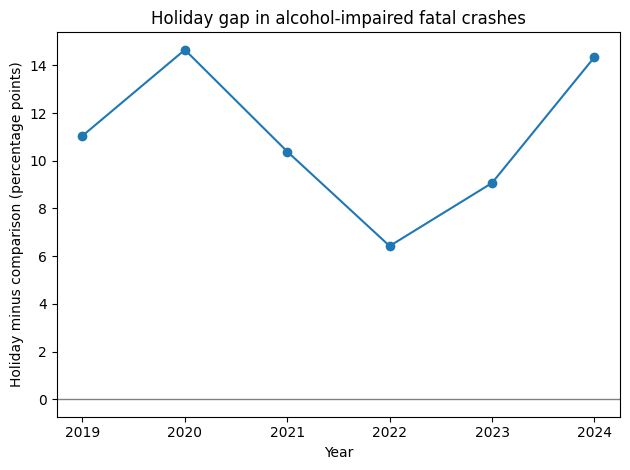

In [15]:
plt.plot(
    yearly_table.index,
    yearly_table["Gap (percentage points)"],
    marker="o"
)

plt.axhline(0, color="gray", linewidth=1)
plt.xticks(yearly_table.index)
plt.title("Holiday gap in alcohol-impaired fatal crashes")
plt.xlabel("Year")
plt.ylabel("Holiday minus comparison (percentage points)")
plt.tight_layout()
plt.show()

We compared six major holidays from 2019 through 2024 with nearby non-holiday dates that fell on the same weekdays. In every year, the percentage of fatal crashes involving alcohol impairment was higher on holiday dates than on the comparison dates.

## Time-of-Day Patterns

We also examined how crashes were distributed across different times of day for holiday and comparison dates. This helps us understand whether the two groups differ in when fatal crashes occur and gives us another crash characteristic that may be useful later in the models.

In [16]:
study_data["TIME_OF_DAY"] = pd.cut(
    study_data["HOUR"],
    bins=[0, 6, 12, 18, 24],
    labels=["Overnight", "Morning", "Afternoon", "Evening"],
    right=False
)

study_data["TIME_OF_DAY"] = study_data["TIME_OF_DAY"].cat.add_categories(["Unknown"])
study_data["TIME_OF_DAY"] = study_data["TIME_OF_DAY"].fillna("Unknown")

time_by_group = pd.crosstab(
    study_data["TIME_OF_DAY"],
    study_data["HOLIDAY_DAY"],
    normalize="columns"
) * 100

time_by_group = time_by_group.rename(columns={0: "Comparison %", 1: "Holiday %"})
time_by_group.round(2)

HOLIDAY_DAY,Comparison %,Holiday %
TIME_OF_DAY,,
Overnight,18.73,26.86
Morning,19.47,13.43
Afternoon,28.81,24.98
Evening,32.31,33.98
Unknown,0.67,0.74


In [17]:
rates_by_time_group = (
    study_data
    .groupby(["TIME_OF_DAY", "GROUP"], observed=True)[outcome_columns]
    .mean()
    .mean(axis=1)
    .mul(100)
    .unstack()
)

rates_by_time_group.round(2)

GROUP,Comparison,Holiday
TIME_OF_DAY,,
Overnight,47.62,55.40
Morning,11.96,20.35
Afternoon,17.05,24.37
Evening,34.86,42.64
Unknown,58.72,60.00


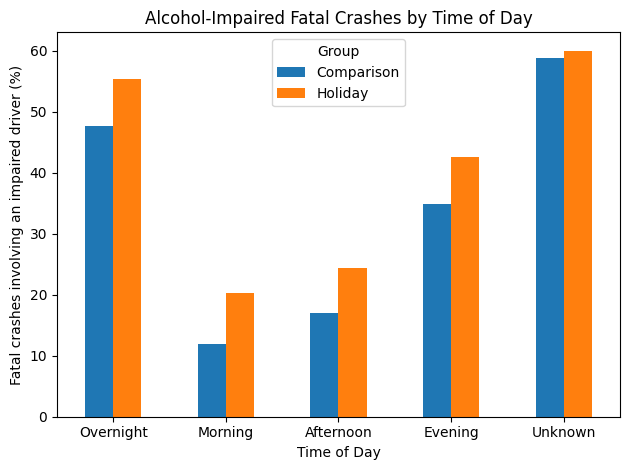

In [18]:
rates_by_time_group.plot(kind="bar")

plt.ylabel("Fatal crashes involving an impaired driver (%)")
plt.xlabel("Time of Day")
plt.title("Alcohol-Impaired Fatal Crashes by Time of Day")
plt.xticks(rotation=0)
plt.legend(title="Group")
plt.tight_layout()
plt.show()

Alcohol impairment differed across times of day for both holiday and comparison crashes. The overnight and evening periods showed higher alcohol-impaired percentages than the morning and afternoon periods. We will consider time of day as a possible predictor in the later models.

#### Alcohol Impairment by Holiday

We next compared the percentage of alcohol-impaired fatal crashes across the six major holidays to see whether the pattern was similar for all holidays.

In [19]:
holiday_only = study_data[
    study_data["HOLIDAY_DAY"] == 1
].copy()

rates_by_holiday = (
    holiday_only
    .groupby("HOLIDAY_NAME")[outcome_columns]
    .mean()
    .mean(axis=1)
    .mul(100)
    .sort_values(ascending=False)
)

rates_by_holiday.round(2)

HOLIDAY_NAME
New Year's Day      46.30
Independence Day    39.35
Thanksgiving Day    38.35
Memorial Day        37.68
Christmas Day       36.33
Labor Day           32.48
dtype: float64

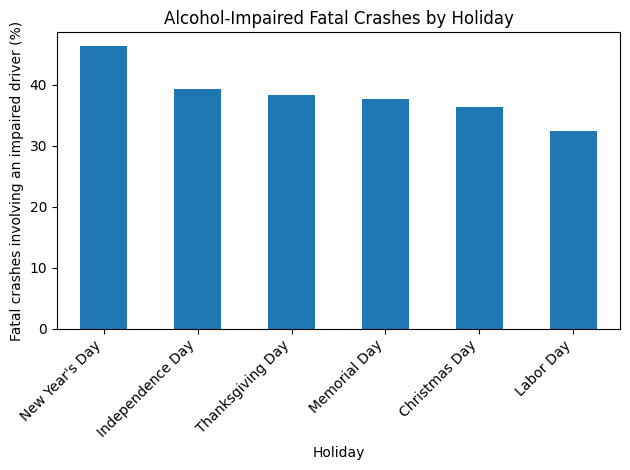

In [20]:
rates_by_holiday.plot(kind="bar")

plt.ylabel("Fatal crashes involving an impaired driver (%)")
plt.xlabel("Holiday")
plt.title("Alcohol-Impaired Fatal Crashes by Holiday")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

The estimated share of fatal crashes involving an impaired driver varied across the six holidays. New Year’s Day had the highest share at 46.30%, and Labor Day had the lowest at 32.48%.

### Alcohol Impairment by Weather

We compared the share of fatal crashes involving alcohol impairment across weather conditions on holiday and comparison dates

In [21]:
rates_by_weather_group = (
    study_data
    .groupby(["WEATHERNAME", "GROUP"])[outcome_columns]
    .mean()
    .mean(axis=1)
    .mul(100)
    .unstack()
)

weather_counts = pd.crosstab(study_data["WEATHERNAME"], study_data["GROUP"])

pd.DataFrame({
    "Comparison crashes": weather_counts["Comparison"],
    "Comparison impaired (%)": rates_by_weather_group["Comparison"],
    "Holiday crashes": weather_counts["Holiday"],
    "Holiday impaired (%)": rates_by_weather_group["Holiday"]
}).round(2)

,Comparison crashes,Comparison impaired (%),Holiday crashes,Holiday impaired (%)
WEATHERNAME,,,,
"Blowing Sand, Soil, Dirt",0,NaN,1,90.00
Blowing Snow,9,20.00,4,27.50
Clear,4900,28.19,2917,38.52
Cloudy,974,27.63,490,39.31
"Fog, Smog, Smoke",82,23.29,83,46.02
Freezing Rain or Drizzle,12,13.33,3,0.00
Not Reported,299,26.15,170,36.71
Other,12,16.67,4,5.00
Rain,551,26.64,311,38.01


#### Prepare Additional Crash Characteristics

We also examined speeding involvement as another crash characteristic that may be useful in the later models. We first checked the vehicle-level FARS files to confirm that the speeding variable was available across all six years.

In [22]:
annual_vehicles = []

for year in range(2019, 2025):
    file_path = f"raw/FARS{year}NationalCSV/vehicle.csv"

    vehicle = pd.read_csv(
        file_path,
        encoding="latin1",
        low_memory=False
    )

    vehicle.columns = vehicle.columns.str.replace(
        "ï»¿", "",
        regex=False
    )

    vehicle["YEAR"] = year
    annual_vehicles.append(vehicle)

vehicle_data = pd.concat(
    annual_vehicles,
    ignore_index=True
)

print(vehicle_data["YEAR"].value_counts().sort_index())
print("Total vehicle rows:", len(vehicle_data))

vehicle_data.to_csv(
    "processed/combined_vehicle_2019_2024.csv",
    index=False
)

YEAR
2019    51623
2020    54552
2021    61802
2022    60765
2023    58508
2024    56011
Name: count, dtype: int64
Total vehicle rows: 343261


In [23]:
print("SPEEDREL values:")
print(
    vehicle_data["SPEEDREL"]
    .value_counts()
    .sort_index()
)

print("\nSPEEDRELNAME values:")
print(
    vehicle_data["SPEEDRELNAME"]
    .value_counts()
)

SPEEDREL values:
SPEEDREL
0    259569
2       796
3     24075
4     26669
5     11647
8      2194
9     18311
Name: count, dtype: int64

SPEEDRELNAME values:
SPEEDRELNAME
No                                             259569
Yes, Too Fast for Conditions                    26669
Yes, Exceeded Speed Limit                       24075
Reported as Unknown                             18311
Yes, Specifics Unknown                          11647
No Driver Present/Unknown if Driver Present      2194
Yes, Racing                                       796
Name: count, dtype: int64


In [24]:
speeding_vehicle = pd.Series(
    np.where(
        vehicle_data["SPEEDREL"].isin([2, 3, 4, 5]),
        1,
        np.where(vehicle_data["SPEEDREL"] == 0, 0, np.nan)
    ),
    index=vehicle_data.index,
    name="SPEEDING_VEHICLE",
    dtype="float64"
)

vehicle_data = vehicle_data.drop(columns="SPEEDING_VEHICLE", errors="ignore")
vehicle_data = pd.concat([vehicle_data, speeding_vehicle], axis=1)

print(vehicle_data["SPEEDING_VEHICLE"].value_counts(dropna=False))

SPEEDING_VEHICLE
0.0    259569
1.0     63187
NaN     20505
Name: count, dtype: int64


#### Create Crash-Level Speeding Variable

Because a crash can involve multiple vehicles, we converted the vehicle-level speeding information into one value per crash. A crash was marked as speeding-related if at least one vehicle was coded as speeding.

In [25]:
speeding_by_crash = (
    vehicle_data
    .groupby(["YEAR", "ST_CASE"])["SPEEDING_VEHICLE"]
    .apply(
        lambda x: 1
        if (x == 1).any()
        else (0 if x.notna().all() else np.nan)
    )
    .reset_index(name="SPEEDING")
)

speeding_by_crash.head()

,YEAR,ST_CASE,SPEEDING
0,2019,10001,1.0
1,2019,10002,1.0
2,2019,10003,1.0
3,2019,10004,0.0
4,2019,10005,1.0


In [26]:
print(speeding_by_crash["SPEEDING"].value_counts(dropna=False))
print("Total crashes:", len(speeding_by_crash))

SPEEDING
0.0    143580
1.0     61948
NaN     17167
Name: count, dtype: int64
Total crashes: 222695


### Adding Speeding to the Study Dataset

We merged the crash-level speeding variable into the holiday/comparison study dataset using `YEAR` and `ST_CASE`.

In [27]:
study_data = study_data.merge(
    speeding_by_crash,
    on=["YEAR", "ST_CASE"],
    how="left",
    validate="one_to_one"
)

print("Rows after merge:", len(study_data))

print("\nSpeeding values:")
print(study_data["SPEEDING"].value_counts(dropna=False))

Rows after merge: 10998

Speeding values:
SPEEDING
0.0    7038
1.0    3121
NaN     839
Name: count, dtype: int64


#### Speeding Involvement

We compared the percentage of speeding-related fatal crashes on holiday dates and comparison dates. This helps us see whether speeding may be another useful characteristic for the later models. Both speeding charts use crashes with a known speeding status. In our study, 839 crashes had an unknown speeding status.

In [28]:
speeding_by_group = (
    study_data
    .groupby("GROUP")["SPEEDING"]
    .mean()
    .mul(100)
)

speeding_by_group.round(2)

GROUP
Comparison    29.08
Holiday       33.55
Name: SPEEDING, dtype: float64

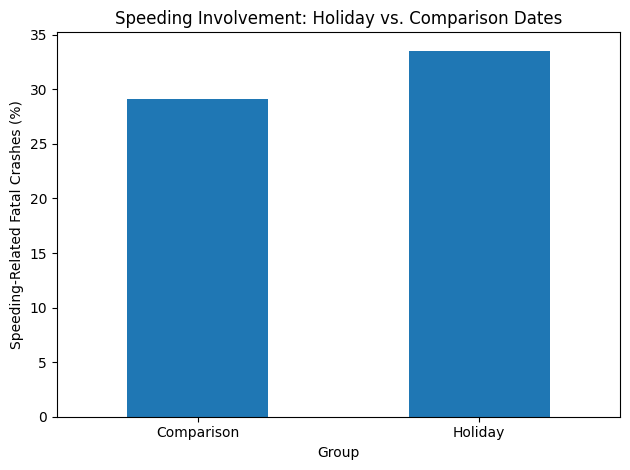

In [29]:
speeding_by_group.plot(kind="bar")

plt.ylabel("Speeding-Related Fatal Crashes (%)")
plt.xlabel("Group")
plt.title("Speeding Involvement: Holiday vs. Comparison Dates")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Alcohol Impairment by Speeding Involvement

We compared alcohol-impaired fatal crashes between speeding-related and non-speeding crashes. This helps us see whether speeding is related to our alcohol-impairment outcome and whether it may be useful in the later models.

In [30]:
rates_by_speeding = (
    study_data
    .groupby("SPEEDING")[outcome_columns]
    .mean()
    .mean(axis=1)
    .mul(100)
)

rates_by_speeding.round(2)

SPEEDING
0.0    26.63
1.0    42.86
dtype: float64

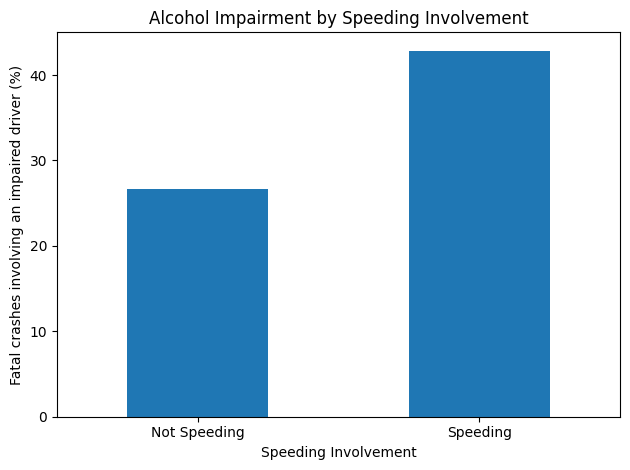

In [31]:
rates_by_speeding.index = rates_by_speeding.index.map({
    0.0: "Not Speeding",
    1.0: "Speeding"
})

rates_by_speeding.plot(
    kind="bar"
)

plt.ylabel("Fatal crashes involving an impaired driver (%)")
plt.xlabel("Speeding Involvement")
plt.title("Alcohol Impairment by Speeding Involvement")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Features For Modeling

In [32]:
unknown_counts = pd.Series({
    "Time of day": (study_data["TIME_OF_DAY"] == "Unknown").sum(),
    "Weather": study_data["WEATHER"].isna().sum(),
    "Speeding": study_data["SPEEDING"].isna().sum()
})

feature_check = pd.DataFrame({
    "Unknown crashes": unknown_counts,
    "Unknown %": (unknown_counts / len(study_data) * 100).round(2)
})

feature_check

,Unknown crashes,Unknown %
Time of day,77,0.70
Weather,520,4.73
Speeding,839,7.63



We chose holiday status and year for our first model. We will let the holiday gap vary by year so we can see how it changed from 2019 to 2024. In a second model, we will add time of day because overnight crashes were more common on holiday dates and more often involved an impaired driver. We explored weather and speeding as possible features for later models.